# Chapitre 11 - Cours 2 : ajuster un réseau de neurones (rétropropagation, weight decay)

Ce notebook couvre les sections 11.4 et 11.5 du livre :

1. les critères d'ajustement (erreur quadratique, entropie croisée, éq. (11.9)–(11.10)) ;
2. la **rétropropagation** du gradient, dérivée pas à pas (éq. (11.11)–(11.15)), implémentée en
   numpy puis **vérifiée** par différences finies ;
3. la descente de gradient (éq. (11.13)) : par lots, en ligne, notion d'époque ;
4. les questions pratiques de la section 11.5 : valeurs initiales, sur-ajustement et arrêt
   précoce, **weight decay** (éq. (11.16)–(11.17)), mise à l'échelle des entrées, minima
   multiples ;
5. l'exemple du **mélange** du chapitre 2 (figures 11.4 et 11.5).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl.ch11_reseaux import (MLP, backprop, forward, gradient_check, init_params,
                              numerical_gradient, one_hot, pack, sigmoid, unpack)

## 1. Le critère à minimiser

Rappelons le modèle (11.5) : pour une observation $x_i$,

$$z_{mi} = \sigma(\alpha_{0m} + \alpha_m^T x_i), \qquad T_{ki} = \beta_{0k} + \beta_k^T z_i, \qquad f_k(x_i) = g_k(T_i),$$

où $z_i = (z_{1i}, \dots, z_{Mi})$. L'ensemble $\theta$ des poids (on dit souvent *poids* pour
*paramètres*) comporte $M(p+1) + K(M+1)$ nombres (éq. (11.8)).

* En **régression**, on minimise la somme des carrés des erreurs

$$R(\theta) = \sum_{k=1}^K \sum_{i=1}^N \big(y_{ik} - f_k(x_i)\big)^2 \qquad \text{(éq. (11.9))}.$$

* En **classification**, avec $y_{ik} = 1$ si l'observation $i$ est de classe $k$ et 0 sinon, on
  utilise soit l'erreur quadratique, soit l'**entropie croisée** (ou déviance)

$$R(\theta) = -\sum_{i=1}^N \sum_{k=1}^K y_{ik} \log f_k(x_i) \qquad \text{(éq. (11.10))},$$

  et le classifieur est $G(x) = \arg\max_k f_k(x)$.

> **Remarque.** Avec la sortie softmax et l'entropie croisée, $R(\theta)$ est exactement
> l'opposé de la log-vraisemblance d'un modèle logistique multinomial **en les unités
> cachées** $z_m$ : ajuster le réseau, c'est faire du maximum de vraisemblance.
>
> En général on ne veut **pas** le minimum global de $R$, qui sur-ajuste presque toujours :
> il faut régulariser, soit par une pénalité, soit en arrêtant l'optimisation tôt (section 4).

## 2. La rétropropagation pas à pas

La méthode générique pour minimiser $R(\theta)$ est la **descente de gradient**. Il faut donc
calculer les dérivées partielles de $R$ par rapport à **chaque** poids. Grâce à la structure en
couches du modèle (composition de fonctions), la **règle de dérivation en chaîne** permet de les
obtenir avec deux balayages du réseau : c'est la **rétropropagation** (*back-propagation*).

Nous traitons l'erreur quadratique (l'entropie croisée fait l'objet de l'exercice 11.3).
Comme $R$ est une somme sur les observations, il suffit de dériver chaque terme :

$$R(\theta) = \sum_{i=1}^N R_i, \qquad R_i = \sum_{k=1}^K \big(y_{ik} - f_k(x_i)\big)^2 \qquad \text{(éq. (11.11))}.$$

### Rappel : la règle de dérivation en chaîne

Si une quantité $R$ dépend d'une variable $u$ **seulement à travers** des quantités
intermédiaires $v_1, \dots, v_K$ (c'est-à-dire $R = \Phi(v_1(u), \dots, v_K(u))$), alors

$$\frac{\partial R}{\partial u} = \sum_{k=1}^K \frac{\partial R}{\partial v_k} \, \frac{\partial v_k}{\partial u}.$$

Le principe de la rétropropagation est de **mémoriser** les dérivées $\partial R / \partial v_k$
par rapport aux quantités intermédiaires, puis de les réutiliser pour toutes les variables
situées « en amont ».

Nous notons $A_{mi} = \alpha_{0m} + \alpha_m^T x_i$ l'entrée de l'unité cachée $m$ (de sorte que
$z_{mi} = \sigma(A_{mi})$), et nous supposons que chaque $g_k$ ne dépend que de $T_k$ (identité ou
sigmoïde : $f_k = g_k(T_k)$). Nous posons aussi $z_{0i} = 1$ et $x_{i0} = 1$ pour traiter les
constantes comme des poids ordinaires.

### Étape 1 : dérivées par rapport aux poids de sortie $\beta_{km}$

Le poids $\beta_{km}$ n'intervient que dans $T_{ki} = \beta_{0k} + \sum_{m'} \beta_{km'} z_{m'i}$, et
$\partial T_{ki} / \partial \beta_{km} = z_{mi}$. Par la règle de la chaîne,

$$\frac{\partial R_i}{\partial \beta_{km}} = \frac{\partial R_i}{\partial T_{ki}} \cdot z_{mi}.$$

Or $T_{ki}$ n'intervient dans $R_i$ qu'à travers le terme $(y_{ik} - g_k(T_{ki}))^2$, d'où

$$\frac{\partial R_i}{\partial T_{ki}} = -2\big(y_{ik} - f_k(x_i)\big)\, g_k'(T_{ki}).$$

Nous obtenons la première formule de (11.12) :

$$\frac{\partial R_i}{\partial \beta_{km}} = -2\big(y_{ik} - f_k(x_i)\big)\, g_k'(\beta_k^T z_i)\, z_{mi}.$$

### Étape 2 : dérivées par rapport aux poids cachés $\alpha_{m\ell}$

Le poids $\alpha_{m\ell}$ n'intervient que dans $A_{mi}$ (avec
$\partial A_{mi}/\partial \alpha_{m\ell} = x_{i\ell}$), donc seulement dans $z_{mi}$. Mais $z_{mi}$
intervient dans **toutes** les sorties $T_{1i}, \dots, T_{Ki}$, avec
$\partial T_{ki}/\partial z_{mi} = \beta_{km}$. La règle de la chaîne donne donc une **somme sur $k$** :

$$
\begin{aligned}
\frac{\partial R_i}{\partial \alpha_{m\ell}}
&= \sum_{k=1}^K \frac{\partial R_i}{\partial T_{ki}} \cdot \frac{\partial T_{ki}}{\partial z_{mi}} \cdot \frac{\partial z_{mi}}{\partial A_{mi}} \cdot \frac{\partial A_{mi}}{\partial \alpha_{m\ell}} \\
&= -\sum_{k=1}^K 2\big(y_{ik} - f_k(x_i)\big)\, g_k'(\beta_k^T z_i)\, \beta_{km}\, \sigma'(\alpha_m^T x_i)\, x_{i\ell},
\end{aligned}
$$

ce qui est la seconde formule de (11.12) (le livre écrit $\alpha_m^T x_i$ pour $A_{mi}$, la constante
étant incluse).

### Étape 3 : les « erreurs » $\delta$ et $s$

On remarque que les deux formules partagent les mêmes facteurs. Posons

$$\delta_{ki} = \frac{\partial R_i}{\partial T_{ki}} = -2\big(y_{ik} - f_k(x_i)\big)\, g_k'(\beta_k^Tz_i), \qquad
s_{mi} = \frac{\partial R_i}{\partial A_{mi}}.$$

Alors (11.12) s'écrit simplement

$$\frac{\partial R_i}{\partial \beta_{km}} = \delta_{ki}\, z_{mi}, \qquad \frac{\partial R_i}{\partial \alpha_{m\ell}} = s_{mi}\, x_{i\ell}
\qquad \text{(éq. (11.14))},$$

et, en comparant avec l'étape 2, les erreurs cachées s'obtiennent à partir des erreurs de sortie :

$$s_{mi} = \sigma'(\alpha_m^T x_i) \sum_{k=1}^K \beta_{km}\, \delta_{ki} \qquad \text{(éq. (11.15))}.$$

C'est l'**équation de rétropropagation** : l'erreur d'une unité cachée est la somme des erreurs
des sorties auxquelles elle est reliée, pondérées par les poids de ces liaisons, puis
multipliée par la pente locale $\sigma'$. Rappelons que $\sigma' = \sigma(1-\sigma)$, donc
$\sigma'(A_{mi}) = z_{mi}(1 - z_{mi})$ : aucune exponentielle supplémentaire n'est nécessaire.

### L'algorithme en deux passes

1. **Passe avant** : avec les poids courants, calculer $A_{mi}$, $z_{mi}$, $T_{ki}$ puis $f_k(x_i)$.
2. **Passe arrière** : calculer les erreurs de sortie $\delta_{ki}$, puis les **rétropropager**
   par (11.15) pour obtenir les $s_{mi}$.
3. Assembler les gradients par (11.14) en sommant sur $i$.

> **Intuition.** Chaque unité n'a besoin que d'informations **locales** : ses entrées dans la
> passe avant, et les erreurs des unités auxquelles elle envoie son signal dans la passe arrière.
> Le coût total est du même ordre que celui d'une seule évaluation du réseau, soit
> $O(N \times \text{nombre de poids})$, au lieu de $O(N \times \text{nombre de poids}^2)$ pour des
> différences finies.

### Forme matricielle

Rangeons les quantités dans des matrices : $\mathbf X$ ($N \times p$), $\mathbf Z$ ($N\times M$, de
terme $z_{mi}$), $\boldsymbol\Delta$ ($N\times K$, de terme $\delta_{ki}$), $\mathbf S$ ($N\times M$),
$\mathbf B$ ($K\times M$, poids $\beta_{km}$ sans les constantes). Alors, en notant $\odot$ le produit
terme à terme et $\mathbf 1$ le vecteur de uns :

$$\mathbf S = (\boldsymbol\Delta\,\mathbf B) \odot \mathbf Z \odot (1 - \mathbf Z), \qquad
\frac{\partial R}{\partial \mathbf B} = \boldsymbol\Delta^T \mathbf Z,\quad \frac{\partial R}{\partial \beta_{0}} = \boldsymbol\Delta^T \mathbf 1, \qquad
\frac{\partial R}{\partial \boldsymbol\alpha} = \mathbf S^T \mathbf X,\quad \frac{\partial R}{\partial \alpha_{0}} = \mathbf S^T\mathbf 1.$$

Voici une implémentation directe (régression, sortie identité, donc $g_k' = 1$).

In [2]:
def passe_avant(alpha, beta, X):
    """alpha : (M, p+1), beta : (K, M+1). Renvoie Z (N, M) et F (N, K)."""
    A = alpha[:, 0] + X @ alpha[:, 1:].T          # A_mi = alpha_0m + alpha_m^T x_i
    Z = 1 / (1 + np.exp(-A))                      # z_mi = sigma(A_mi)
    F = beta[:, 0] + Z @ beta[:, 1:].T            # f_k(x_i) = T_ki (sortie identité)
    return Z, F

In [3]:
def retropropagation(alpha, beta, X, Y):
    """Erreur quadratique R et gradients (dR/dalpha, dR/dbeta)."""
    Z, F = passe_avant(alpha, beta, X)
    R = np.sum((Y - F) ** 2)
    Delta = -2 * (Y - F)                          # delta_ki (g' = 1)
    S = (Delta @ beta[:, 1:]) * Z * (1 - Z)       # s_mi, éq. (11.15)
    g_beta = np.column_stack([Delta.sum(axis=0), Delta.T @ Z])   # éq. (11.14)
    g_alpha = np.column_stack([S.sum(axis=0), S.T @ X])
    return R, g_alpha, g_beta

### Vérification par différences finies

Pour s'assurer qu'aucune erreur ne s'est glissée dans les dérivées, on compare au gradient
**numérique** obtenu par différences finies centrées : pour chaque poids $\theta_j$,

$$\frac{\partial R}{\partial \theta_j} \approx \frac{R(\theta + \varepsilon e_j) - R(\theta - \varepsilon e_j)}{2\varepsilon},$$

où $e_j$ est le $j$-ième vecteur de la base canonique. Par la formule de Taylor à l'ordre 3,
$R(\theta \pm \varepsilon e_j) = R(\theta) \pm \varepsilon\,\partial_j R + \tfrac{\varepsilon^2}{2} \partial_j^2 R \pm \tfrac{\varepsilon^3}{6}\partial_j^3 R + o(\varepsilon^3)$ ;
les termes pairs se compensent dans la différence, et l'erreur de l'approximation est en $O(\varepsilon^2)$.

In [4]:
rng = np.random.RandomState(0)
N, p, M, K = 20, 3, 4, 2
X = rng.randn(N, p)
Y = rng.randn(N, K)
alpha = rng.uniform(-0.7, 0.7, (M, p + 1))
beta = rng.uniform(-0.7, 0.7, (K, M + 1))

R, g_alpha, g_beta = retropropagation(alpha, beta, X, Y)

def R_de_theta(theta):
    a = theta[:M * (p + 1)].reshape(M, p + 1)
    b = theta[M * (p + 1):].reshape(K, M + 1)
    return retropropagation(a, b, X, Y)[0]

theta = np.concatenate([alpha.ravel(), beta.ravel()])
g_num = numerical_gradient(R_de_theta, theta, eps=1e-5)
g_bp = np.concatenate([g_alpha.ravel(), g_beta.ravel()])
print("nombre de poids :", theta.size)
print("écart max |rétropropagation - différences finies| :", np.max(np.abs(g_bp - g_num)))

nombre de poids : 26
écart max |rétropropagation - différences finies| : 6.217462100721605e-10


Les deux gradients coïncident à $10^{-9}$ près. Comparons aussi avec la fonction `backprop` du
module `esl.ch11_reseaux`, qui gère en plus les sorties sigmoïde/softmax, l'entropie croisée et le
weight decay.

In [5]:
R_mod, grads = backprop({"alpha": alpha, "beta": beta}, X, Y, output="identity", loss="squared")
print("même R :", np.isclose(R, R_mod))
print("mêmes gradients :", np.allclose(grads["alpha"], g_alpha), np.allclose(grads["beta"], g_beta))

même R : True
mêmes gradients : True True


Comment choisir $\varepsilon$ ? Trop grand, l'erreur de troncature $O(\varepsilon^2)$ domine ; trop
petit, ce sont les erreurs d'arrondi (de l'ordre de $10^{-16}/\varepsilon$) qui dominent. La courbe
de l'erreur relative en fonction de $\varepsilon$ a donc une forme de « V » en échelle log-log.

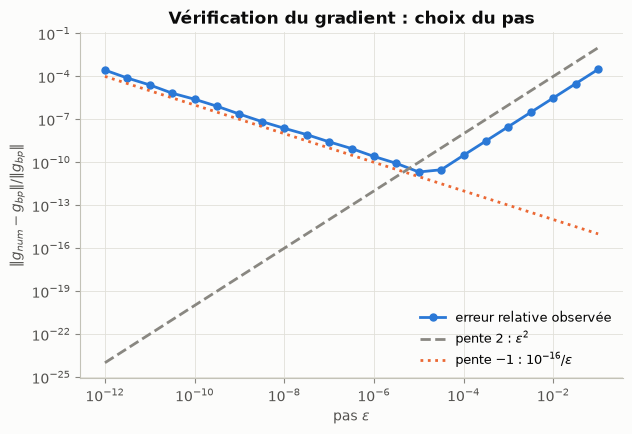

In [6]:
eps_grid = np.logspace(-12, -1, 23)
rel = []
for e in eps_grid:
    gn = numerical_gradient(R_de_theta, theta, eps=e)
    rel.append(np.linalg.norm(gn - g_bp) / np.linalg.norm(g_bp))
fig, ax = plt.subplots()
ax.loglog(eps_grid, rel, "o-", color=BLUE, label="erreur relative observée")
ax.loglog(eps_grid, eps_grid ** 2, "--", color=GRAY, label=r"pente 2 : $\varepsilon^2$")
ax.loglog(eps_grid, 1e-16 / eps_grid, ":", color=ORANGE, label=r"pente $-1$ : $10^{-16}/\varepsilon$")
ax.set_xlabel(r"pas $\varepsilon$")
ax.set_ylabel(r"$\|g_{num} - g_{bp}\| / \|g_{bp}\|$")
ax.set_title("Vérification du gradient : choix du pas")
ax.legend()
plt.show()

Le module fournit `gradient_check`, utilisé dans les tests unitaires pour toutes les combinaisons
sortie/perte :

In [7]:
Yc = one_hot(rng.randint(0, 3, N), 3)
for out, loss, YY in [("identity", "squared", Y), ("softmax", "cross_entropy", Yc),
                      ("sigmoid", "squared", Yc), ("softmax", "squared", Yc)]:
    par = init_params(p, M, YY.shape[1], rng)
    print("%-9s + %-13s : erreur relative = %.1e"
          % (out, loss, gradient_check(par, X, YY, out, loss, weight_decay=0.1)))

identity  + squared       : erreur relative = 1.4e-10
softmax   + cross_entropy : erreur relative = 3.8e-10
sigmoid   + squared       : erreur relative = 3.0e-10
softmax   + squared       : erreur relative = 6.0e-10


> **À retenir.** La rétropropagation n'est rien d'autre que la règle de dérivation en chaîne,
> organisée pour réutiliser les calculs : une passe avant (valeurs des unités) puis une passe
> arrière (erreurs $\delta$ puis $s = \sigma' \cdot \sum_k \beta_{km}\delta_k$). On vérifie toujours une
> implémentation par différences finies.

## 3. Descente de gradient

Muni du gradient, l'itération de descente de gradient s'écrit, à l'étape $r+1$,

$$\beta_{km}^{(r+1)} = \beta_{km}^{(r)} - \gamma_r \sum_{i=1}^N \frac{\partial R_i}{\partial \beta_{km}^{(r)}}, \qquad
\alpha_{m\ell}^{(r+1)} = \alpha_{m\ell}^{(r)} - \gamma_r \sum_{i=1}^N \frac{\partial R_i}{\partial \alpha_{m\ell}^{(r)}}
\qquad \text{(éq. (11.13))},$$

où $\gamma_r > 0$ est le **taux d'apprentissage** (*learning rate*).

* **Apprentissage par lots** (*batch*) : la mise à jour utilise la somme sur **toutes** les
  observations, comme dans (11.13). Le taux $\gamma_r$ est en général constant.
* **Apprentissage en ligne** (*online*) : on traite les observations **une par une**, la somme
  étant remplacée par un seul terme. Une **époque** désigne un passage complet sur les données.
  C'est une forme d'**approximation stochastique** (Robbins et Monro) : la convergence est
  assurée si $\gamma_r \to 0$, $\sum_r \gamma_r = \infty$ et $\sum_r \gamma_r^2 < \infty$ (par exemple
  $\gamma_r = 1/r$).

La descente de gradient est souvent **lente** ; on lui préfère des méthodes de type
**gradient conjugué** ou **à métrique variable** (quasi-Newton, comme BFGS), qui accélèrent la
convergence sans calculer la matrice hessienne (trop grande). Notre classe `MLP` propose les
trois : `method="gd"` (par lots, pas appliqué au gradient moyen), `method="sgd"` (mini-lots, en
ligne si `batch_size=1`) et `method="lbfgs"` (quasi-Newton à mémoire limitée).

Comparons-les sur la simulation « somme de deux sigmoïdes » de la section 11.6
($N = 100$, $p = 2$, rapport signal sur bruit 4), avec $M = 4$ unités cachées et les mêmes poids
initiaux.

In [8]:
a1, a2 = np.array([3.0, 3.0]), np.array([3.0, -3.0])

def f_sig(X):
    return sigmoid(X @ a1) + sigmoid(X @ a2)

rng = np.random.RandomState(0)
sigma2 = np.var(f_sig(rng.randn(200_000, 2))) / 4
Xs = rng.randn(100, 2)
ys = f_sig(Xs) + np.sqrt(sigma2) * rng.randn(100)

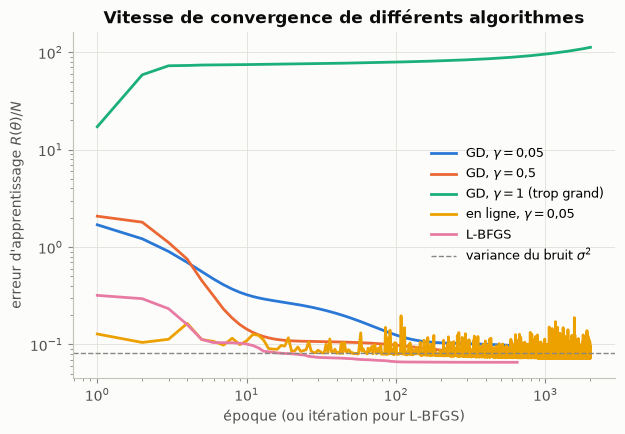

In [9]:
courbes = {}
for nom, kw in [("GD, $\\gamma=0{,}05$", dict(method="gd", lr=0.05, n_epochs=2000)),
                ("GD, $\\gamma=0{,}5$", dict(method="gd", lr=0.5, n_epochs=2000)),
                ("GD, $\\gamma=1$ (trop grand)", dict(method="gd", lr=1.0, n_epochs=2000)),
                ("en ligne, $\\gamma=0{,}05$", dict(method="sgd", batch_size=1, lr=0.05, n_epochs=2000)),
                ("L-BFGS", dict(method="lbfgs", max_iter=2000))]:
    net = MLP(n_hidden=4, random_state=1).fit(Xs, ys, **kw)
    courbes[nom] = np.array(net.history_) / len(ys)

fig, ax = plt.subplots()
for c, (nom, h) in zip(COLORS, courbes.items()):
    ax.plot(np.arange(1, len(h) + 1), h, color=c, label=nom)
ax.axhline(sigma2, ls="--", color=GRAY, lw=1, label=r"variance du bruit $\sigma^2$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("époque (ou itération pour L-BFGS)")
ax.set_ylabel(r"erreur d'apprentissage $R(\theta)/N$")
ax.set_title("Vitesse de convergence de différents algorithmes")
ax.legend()
plt.show()

Le quasi-Newton converge en quelques centaines d'itérations. La descente de gradient par lots
est bien plus lente, et très sensible au taux $\gamma$ : trop petit, elle avance lentement ; trop
grand ($\gamma = 1$), elle « saute » par-dessus les vallées du critère et l'erreur **augmente**. L'apprentissage en ligne effectue $N = 100$ mises à jour
par époque et progresse donc plus vite par époque que le gradient par lots, mais oscille autour
du minimum car son pas est constant. Dans la suite, nous utilisons surtout L-BFGS.

## 4. Quelques questions pratiques (section 11.5)

### 4.1 Valeurs initiales

* Si **tous** les poids valent exactement 0, toutes les unités cachées valent $\sigma(0) = 1/2$, et
  les erreurs rétropropagées $s_{mi} = \sigma'(A_{mi})\sum_k \beta_{km}\delta_{ki}$ sont nulles
  (car $\beta_{km} = 0$) : le gradient par rapport aux $\alpha$ est **nul**. Les $\beta_{km}$, eux,
  reçoivent tous le même gradient $\sum_i \delta_{ki}\cdot \tfrac12$. Par récurrence, les unités
  cachées reçoivent à chaque itération exactement les mêmes mises à jour : elles restent
  **identiques** (symétrie parfaite), et le réseau à $M$ unités ne vaut jamais mieux qu'un réseau
  à **une seule** unité. (Avec un algorithme qui ne modifierait que les poids de gradient non
  nul à partir de l'origine exacte, rien ne bougerait du tout côté $\alpha$ à la première
  itération : c'est le blocage décrit par le livre.)